In [50]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

In [112]:
sheets= pd.read_excel('Regional Sales Dataset.xlsx', sheet_name=None)

In [113]:
#Assign datframe to each sheets
df_sales = sheets['Sales Orders']
df_customers= sheets['Customers']
df_products= sheets['Products']
df_state_reg= sheets['State Regions']
df_regions= sheets['Regions']
df_budgets= sheets['2017 Budgets']

df_list = [df_sales,df_customers, df_products, df_state_reg, df_regions, df_budgets ]

In [114]:
type(sheets)

dict

In [115]:
print(f'df_sales shape is {df_sales.shape}')    
print(f'df_customers shape is {df_customers.shape}') 
print(f'df_products shape is {df_products.shape}')  
print(f'df_state_reg shape is {df_state_reg.shape}')  
print(f'df_regions shape is {df_regions.shape}')  
print(f'df_budgets shape is {df_budgets.shape}')  

df_sales shape is (64104, 12)
df_customers shape is (175, 2)
df_products shape is (30, 2)
df_state_reg shape is (49, 3)
df_regions shape is (994, 15)
df_budgets shape is (30, 2)


In [116]:
for df in df_list: 
    print(f'The head of df is \n {df.head(5)} \n  ')

The head of df is 
     OrderNumber  OrderDate  Customer Name Index      Channel Currency Code  \
0   SO - 000225 2014-01-01                  126    Wholesale           USD   
1  SO - 0003378 2014-01-01                   96  Distributor           USD   
2  SO - 0005126 2014-01-01                    8    Wholesale           USD   
3  SO - 0005614 2014-01-01                   42       Export           USD   
4  SO - 0005781 2014-01-01                   73    Wholesale           USD   

  Warehouse Code  Delivery Region Index  Product Description Index  \
0         AXW291                    364                         27   
1         AXW291                    488                         20   
2         AXW291                    155                         26   
3         AXW291                    473                          7   
4         AXW291                    256                          8   

   Order Quantity  Unit Price  Line Total  Total Unit Cost  
0               6      2499.1

In [117]:
# Correct the state region dataframe header 

new_header = df_state_reg.iloc[0]
df_state_reg.columns = new_header
df_state_reg= df_state_reg[1:].reset_index(drop=True)
df_state_reg.head(5)

,State Code,State,Region
0,AL,Alabama,South
1,AR,Arkansas,South
2,AZ,Arizona,West
3,CA,California,West
4,CO,Colorado,West


In [118]:
for df in df_list :
    print(df.columns)

Index(['OrderNumber', 'OrderDate', 'Customer Name Index', 'Channel',
       'Currency Code', 'Warehouse Code', 'Delivery Region Index',
       'Product Description Index', 'Order Quantity', 'Unit Price',
       'Line Total', 'Total Unit Cost'],
      dtype='str')
Index(['Customer Index', 'Customer Names'], dtype='str')
Index(['Index', 'Product Name'], dtype='str')
Index(['State Code', 'State', 'Region'], dtype='str', name=0)
Index(['id', 'name', 'county', 'state_code', 'state', 'type', 'latitude',
       'longitude', 'area_code', 'population', 'households', 'median_income',
       'land_area', 'water_area', 'time_zone'],
      dtype='str')
Index(['Product Name', '2017 Budgets'], dtype='str')


# Check Nulls 

In [119]:

for df in df_list: 
    if df.isnull().sum().sum() != 0 :
        print(df)
else :
    print('No null columns / dataframe ')

No null columns / dataframe 


# Data Cleaning and Wrangling 

In [120]:
# Merge with customers 

df = df_sales.merge(
    df_customers, 
    how= 'left' , 
    left_on = 'Customer Name Index',
    right_on = 'Customer Index'
)

In [121]:
df.head()

,OrderNumber,OrderDate,Customer Name Index,Channel,Currency Code,Warehouse Code,Delivery Region Index,Product Description Index,Order Quantity,Unit Price,Line Total,Total Unit Cost,Customer Index,Customer Names
0,SO - 000225,2014-01-01,126,Wholesale,USD,AXW291,364,27,6,2499.1,14994.6,1824.343,126,Rhynoodle Ltd
1,SO - 0003378,2014-01-01,96,Distributor,USD,AXW291,488,20,11,2351.7,25868.7,1269.918,96,Thoughtmix Ltd
2,SO - 0005126,2014-01-01,8,Wholesale,USD,AXW291,155,26,6,978.2,5869.2,684.740,8,Amerisourc Corp
3,SO - 0005614,2014-01-01,42,Export,USD,AXW291,473,7,7,2338.3,16368.1,1028.852,42,Colgate-Pa Group
4,SO - 0005781,2014-01-01,73,Wholesale,USD,AXW291,256,8,8,2291.4,18331.2,1260.270,73,Deseret Group


In [122]:
# Merge with Products 

df = df.merge(
    df_products, 
    how= 'left' , 
    left_on = 'Product Description Index',
    right_on = 'Index'
)



In [123]:
df= df.merge(
    df_regions, 
    how= 'left',
    left_on = 'Delivery Region Index',
    right_on = 'id'
)



In [124]:
df= df.merge(
    df_state_reg[['State Code','Region']], 
    how = 'left',
    left_on = 'state_code', 
    right_on = 'State Code'
)

In [125]:
df= df.merge(
    df_budgets, 
    how= 'left',
    on='Product Name'
)

In [126]:
df.head()

,OrderNumber,OrderDate,Customer Name Index,Channel,Currency Code,Warehouse Code,Delivery Region Index,Product Description Index,Order Quantity,Unit Price,...,area_code,population,households,median_income,land_area,water_area,time_zone,State Code,Region,2017 Budgets
0,SO - 000225,2014-01-01,126,Wholesale,USD,AXW291,364,27,6,2499.1,...,912,145674,52798,36466,268318796,13908113,America/New York,GA,South,964940.231
1,SO - 0003378,2014-01-01,96,Distributor,USD,AXW291,488,20,11,2351.7,...,317,55586,20975,54176,72276415,1883,America/Indiana/Indianapolis,IN,Midwest,2067108.120
2,SO - 0005126,2014-01-01,8,Wholesale,USD,AXW291,155,26,6,978.2,...,925,79510,26020,124759,62489257,386195,America/Los Angeles,CA,West,5685138.270
3,SO - 0005614,2014-01-01,42,Export,USD,AXW291,473,7,7,2338.3,...,812,84067,30232,30019,60221613,475857,America/Indiana/Indianapolis,IN,Midwest,889737.555
4,SO - 0005781,2014-01-01,73,Wholesale,USD,AXW291,256,8,8,2291.4,...,959,58007,24141,63158,70972793,720300,America/New York,CT,Northeast,1085037.329


In [127]:
df.columns

Index(['OrderNumber', 'OrderDate', 'Customer Name Index', 'Channel',
       'Currency Code', 'Warehouse Code', 'Delivery Region Index',
       'Product Description Index', 'Order Quantity', 'Unit Price',
       'Line Total', 'Total Unit Cost', 'Customer Index', 'Customer Names',
       'Index', 'Product Name', 'id', 'name', 'county', 'state_code', 'state',
       'type', 'latitude', 'longitude', 'area_code', 'population',
       'households', 'median_income', 'land_area', 'water_area', 'time_zone',
       'State Code', 'Region', '2017 Budgets'],
      dtype='str')

In [128]:
# Remove the redundant columns 
cols_to_drop = ['Customer Index', 'Index', 'id', 'State Code']
df= df.drop(columns= cols_to_drop)
df.head(5)

,OrderNumber,OrderDate,Customer Name Index,Channel,Currency Code,Warehouse Code,Delivery Region Index,Product Description Index,Order Quantity,Unit Price,...,longitude,area_code,population,households,median_income,land_area,water_area,time_zone,Region,2017 Budgets
0,SO - 000225,2014-01-01,126,Wholesale,USD,AXW291,364,27,6,2499.1,...,-81.09983,912,145674,52798,36466,268318796,13908113,America/New York,South,964940.231
1,SO - 0003378,2014-01-01,96,Distributor,USD,AXW291,488,20,11,2351.7,...,-86.10665,317,55586,20975,54176,72276415,1883,America/Indiana/Indianapolis,Midwest,2067108.120
2,SO - 0005126,2014-01-01,8,Wholesale,USD,AXW291,155,26,6,978.2,...,-121.87468,925,79510,26020,124759,62489257,386195,America/Los Angeles,West,5685138.270
3,SO - 0005614,2014-01-01,42,Export,USD,AXW291,473,7,7,2338.3,...,-86.52639,812,84067,30232,30019,60221613,475857,America/Indiana/Indianapolis,Midwest,889737.555
4,SO - 0005781,2014-01-01,73,Wholesale,USD,AXW291,256,8,8,2291.4,...,-72.52443,959,58007,24141,63158,70972793,720300,America/New York,Northeast,1085037.329


In [129]:
# Convert column  names to lower case 

df.columns = df.columns.str.lower()
df.columns

Index(['ordernumber', 'orderdate', 'customer name index', 'channel',
       'currency code', 'warehouse code', 'delivery region index',
       'product description index', 'order quantity', 'unit price',
       'line total', 'total unit cost', 'customer names', 'product name',
       'name', 'county', 'state_code', 'state', 'type', 'latitude',
       'longitude', 'area_code', 'population', 'households', 'median_income',
       'land_area', 'water_area', 'time_zone', 'region', '2017 budgets'],
      dtype='str')

In [130]:
cols_to_keep = [
    'ordernumber', 
    'orderdate',
    'customer names',
    'channel',
    'order quantity',
    'unit price',
    'line total',
    'total unit cost',
    'product name',
    'county',
    'state_code',
    'state',
    'latitude',
    'longitude',
    'region',
    '2017 budgets'
]

In [131]:
df= df[cols_to_keep]
df.head()

,ordernumber,orderdate,customer names,channel,order quantity,unit price,line total,total unit cost,product name,county,state_code,state,latitude,longitude,region,2017 budgets
0,SO - 000225,2014-01-01,Rhynoodle Ltd,Wholesale,6,2499.1,14994.6,1824.343,Product 27,Chatham County,GA,Georgia,32.08354,-81.09983,South,964940.231
1,SO - 0003378,2014-01-01,Thoughtmix Ltd,Distributor,11,2351.7,25868.7,1269.918,Product 20,Johnson County,IN,Indiana,39.61366,-86.10665,Midwest,2067108.120
2,SO - 0005126,2014-01-01,Amerisourc Corp,Wholesale,6,978.2,5869.2,684.740,Product 26,Alameda County,CA,California,37.66243,-121.87468,West,5685138.270
3,SO - 0005614,2014-01-01,Colgate-Pa Group,Export,7,2338.3,16368.1,1028.852,Product 7,Monroe County,IN,Indiana,39.16533,-86.52639,Midwest,889737.555
4,SO - 0005781,2014-01-01,Deseret Group,Wholesale,8,2291.4,18331.2,1260.270,Product 8,Hartford County,CT,Connecticut,41.77524,-72.52443,Northeast,1085037.329


In [134]:
df.loc[df['orderdate'].dt.year != 2017 , '2017 budgets']= pd.NA

In [136]:
df.head(1)

,ordernumber,orderdate,customer names,channel,order quantity,unit price,line total,total unit cost,product name,county,state_code,state,latitude,longitude,region,2017 budgets
0,SO - 000225,2014-01-01,Rhynoodle Ltd,Wholesale,6,2499.1,14994.6,1824.343,Product 27,Chatham County,GA,Georgia,32.08354,-81.09983,South,NaN


In [138]:
df= df.rename(columns={
    'ordernumber': 'order_number',
    'orderdate': 'order_date',
    'customer names': 'customer_name',
    'order quantity': 'order_quantity',
    'unit price': 'unit_price',
    'line total': 'revenue',
    'total unit cost': 'cost',
    'state code':'state',
    'state': 'state_name',
    'latitude':'lat',
    'longitude':'lon',
    '2017 budget':'budget'
})

In [139]:
df.head(5)

,order_number,order_date,customer_name,channel,order_quantity,unit_price,revenue,cost,product name,county,state_code,state_name,lat,lon,region,2017 budgets
0,SO - 000225,2014-01-01,Rhynoodle Ltd,Wholesale,6,2499.1,14994.6,1824.343,Product 27,Chatham County,GA,Georgia,32.08354,-81.09983,South,NaN
1,SO - 0003378,2014-01-01,Thoughtmix Ltd,Distributor,11,2351.7,25868.7,1269.918,Product 20,Johnson County,IN,Indiana,39.61366,-86.10665,Midwest,NaN
2,SO - 0005126,2014-01-01,Amerisourc Corp,Wholesale,6,978.2,5869.2,684.740,Product 26,Alameda County,CA,California,37.66243,-121.87468,West,NaN
3,SO - 0005614,2014-01-01,Colgate-Pa Group,Export,7,2338.3,16368.1,1028.852,Product 7,Monroe County,IN,Indiana,39.16533,-86.52639,Midwest,NaN
4,SO - 0005781,2014-01-01,Deseret Group,Wholesale,8,2291.4,18331.2,1260.270,Product 8,Hartford County,CT,Connecticut,41.77524,-72.52443,Northeast,NaN


In [140]:
df_2017 = df[df['order_date'].dt.year == 2017]
df_2017

,order_number,order_date,customer_name,channel,order_quantity,unit_price,revenue,cost,product name,county,state_code,state_name,lat,lon,region,2017 budgets
46363,SO - 0002544,2017-01-01,NCS Group,Wholesale,6,1239.5,7437.0,1028.785,Product 30,Hudson County,NJ,New Jersey,40.77955,-74.02375,Northeast,1011609.684
46364,SO - 0006431,2017-01-01,Epic Group,Wholesale,5,1829.1,9145.5,1207.206,Product 13,Mesa County,CO,Colorado,39.06387,-108.55065,West,3720639.645
46365,SO - 0007491,2017-01-01,State Ltd,Wholesale,9,2412.0,21708.0,1664.280,Product 15,Los Angeles County,CA,California,33.96168,-118.35313,West,3299478.315
46366,SO - 0008741,2017-01-01,Fivebridge Ltd,Wholesale,8,904.5,7236.0,750.735,Product 8,Dubuque County,IA,Iowa,42.50056,-90.66457,Midwest,1085037.329
46367,SO - 0009295,2017-01-01,Tagfeed Ltd,Wholesale,12,1112.2,13346.4,811.906,Product 2,Hernando County,FL,Florida,28.47689,-82.52546,South,3050087.565
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61621,SO - 0003524,2017-12-31,Zooveo Company,Wholesale,9,984.9,8864.1,512.148,Product 1,Jackson County/Clay County,MO,Missouri,39.08547,-94.35210,Midwest,3016489.209
61622,SO - 0004785,2017-12-31,Wordware Company,Wholesale,12,201.0,2412.0,90.450,Product 3,Philadelphia County,PA,Pennsylvania,39.95234,-75.16379,Northeast,2642352.432
61623,SO - 0004950,2017-12-31,Dynazzy Company,Distributor,9,3825.7,34431.3,3098.817,Product 6,Volusia County,FL,Florida,29.13832,-80.99561,South,1672229.416
61624,SO - 0006829,2017-12-31,Pixoboo Corp,Distributor,5,1835.8,9179.0,972.974,Product 6,New Haven County,CT,Connecticut,41.22509,-73.06111,Northeast,1672229.416


# Feature Engineering

In [141]:
df['total_cost']= df['cost']*df['order_quantity']

In [142]:
df['profit']= df['revenue']-df['total_cost']

In [144]:
df['profit_margin_pct'] = df['profit']/df['revenue']*100

In [145]:
df.head(2)

,order_number,order_date,customer_name,channel,order_quantity,unit_price,revenue,cost,product name,county,state_code,state_name,lat,lon,region,2017 budgets,total_cost,profit,profit_margin_pct
0,SO - 000225,2014-01-01,Rhynoodle Ltd,Wholesale,6,2499.1,14994.6,1824.343,Product 27,Chatham County,GA,Georgia,32.08354,-81.09983,South,NaN,10946.058,4048.542,27.0
1,SO - 0003378,2014-01-01,Thoughtmix Ltd,Distributor,11,2351.7,25868.7,1269.918,Product 20,Johnson County,IN,Indiana,39.61366,-86.10665,Midwest,NaN,13969.098,11899.602,46.0


# EDA

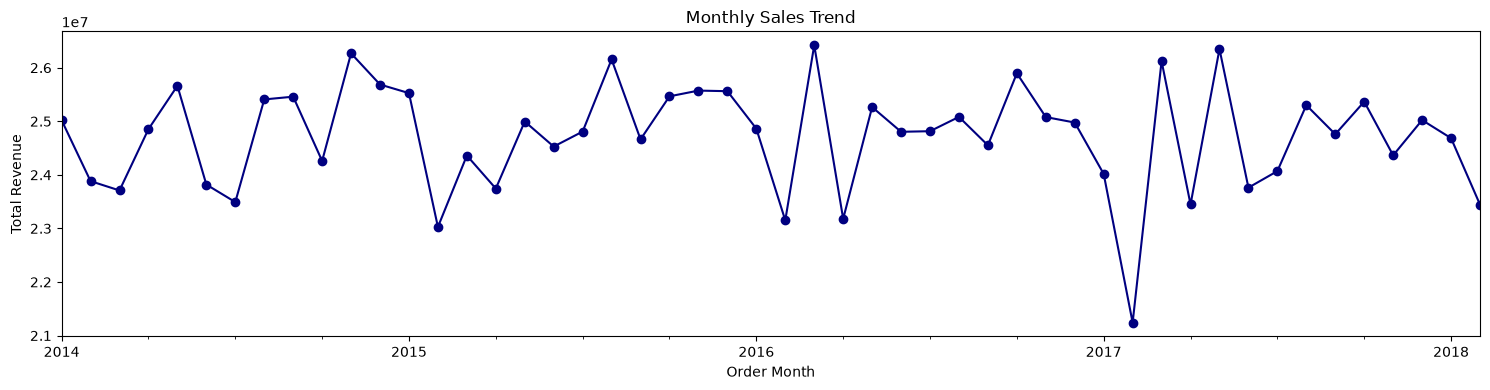

In [157]:
df['order_month'] = df['order_date'].dt.to_period("M")

monthly_sales = df.groupby('order_month')['revenue'].sum()

plt.figure(figsize=(15,4))

monthly_sales.plot(marker='o', color='navy')

plt.xlabel('Order Month')
plt.ylabel('Total Revenue')
plt.title('Monthly Sales Trend')
plt.tight_layout()
plt.show()


## Insights 
1. The sales range between 23 million to 26 million
2. There is a downward spike at beginning of the year around in the month of January.
3. The quarter 3 has an upward spike altogether .
4. Quarter 2 sees an even sales for each year .
5. January 2017 saw the lowest sales . 


In [170]:
#Jan 2017 
df_lowest_phase = df[df['order_date'].between('2017-01-01', '2017-01-31')]
df_lowest_phase.shape


(1234, 20)

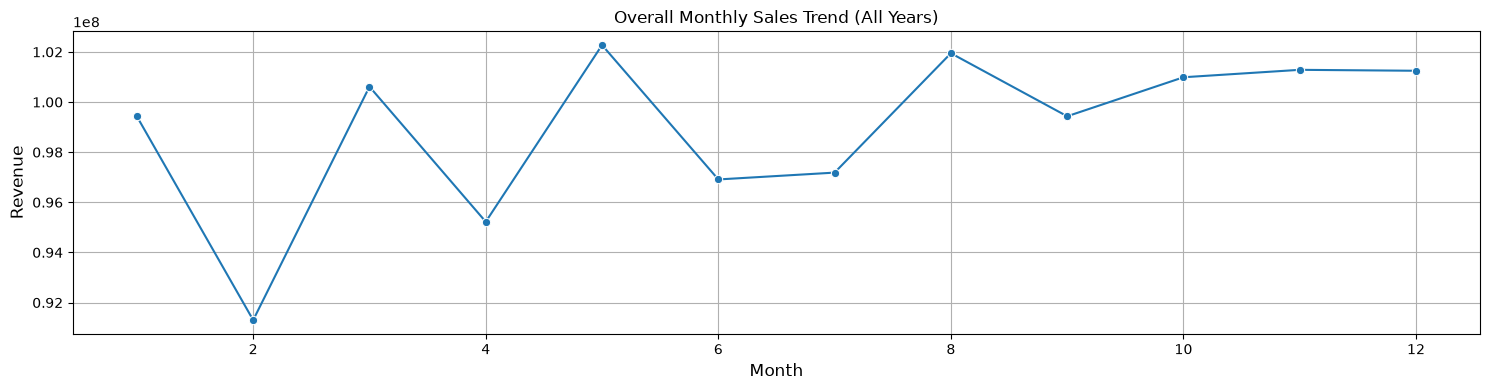

In [180]:
# Overall Monthly sales 
df['month']= df['order_date'].dt.month
df['month_name']= df['order_date'].dt.month_name
monthly_sales_overall= df[df['order_date'].dt.year != 2018].groupby('month')['revenue'].sum().reset_index()
plt.figure(figsize= (15,4))
sns.lineplot(data= monthly_sales_overall , x= 'month',y= 'revenue', marker= 'o')
plt.title('Overall Monthly Sales Trend (All Years)')
plt.xlabel('Month', fontsize= 12 )
plt.ylabel('Revenue', fontsize=12)
plt.grid(True)
plt.tight_layout()

In [184]:
# Sales by chanel

channel_sales = df.groupby('channel')['revenue'].sum().sort_values()

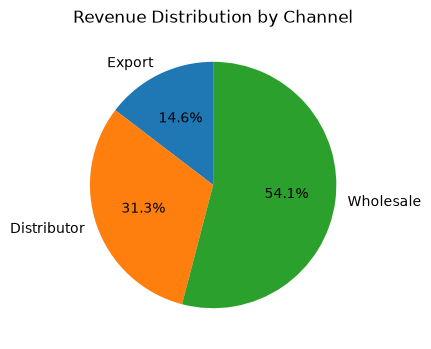

In [186]:
plt.figure(figsize=(8, 8))

channel_sales.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    figsize=(15, 4)
)

plt.title('Revenue Distribution by Channel')
plt.ylabel('')
plt.show()

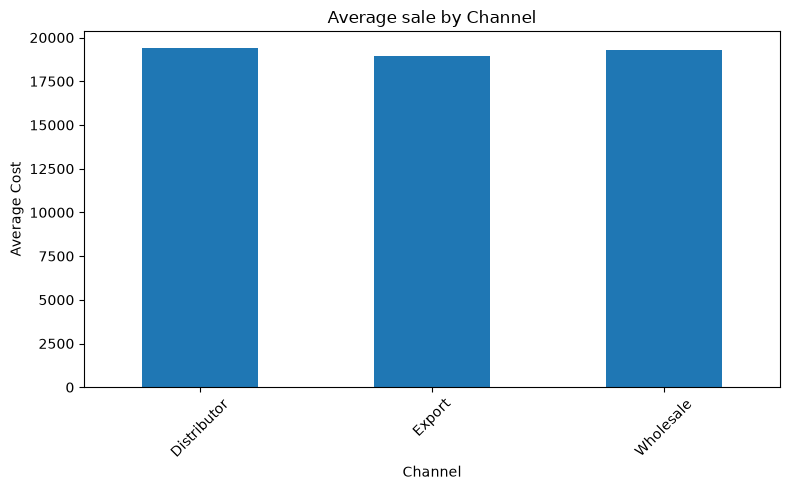

In [189]:
# Average order value by channel 

channel_avg_order = df.groupby('channel')['revenue'].mean()
channel_avg_order.plot(kind='bar', figsize=(8, 5))

plt.title('Average sale by Channel')
plt.xlabel('Channel')
plt.ylabel('Average Cost')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

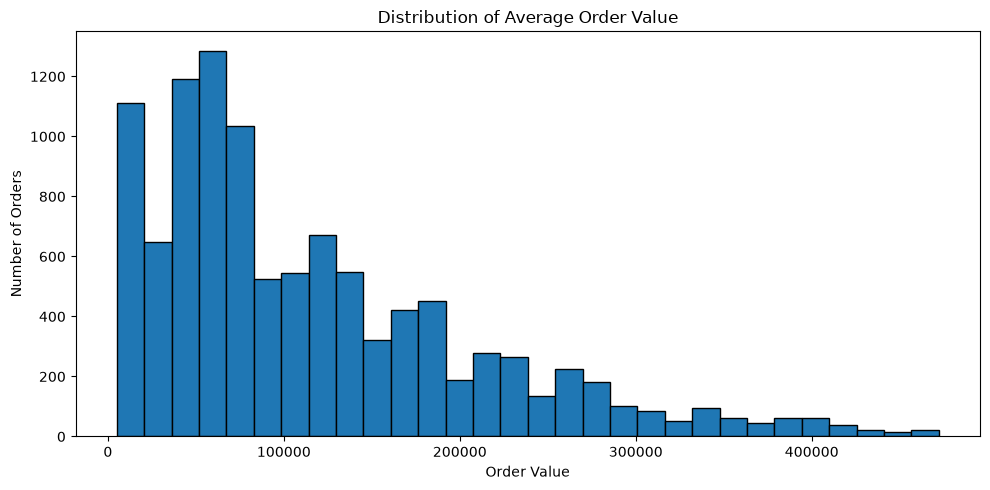

In [190]:
## Average order value (AOV)

aov = df.groupby('order_number')['revenue'].sum()

plt.figure(figsize=(10, 5))
plt.hist(aov, bins=30, edgecolor='black')

plt.title('Distribution of Average Order Value')
plt.xlabel('Order Value')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()


In [191]:
# Top 10 states by Revenue and order count 
# Top and bottom 10 customers by revenue 
# Customer segemntation revenue vs profit margin 
# correlation Heatmap 

df.columns

Index(['order_number', 'order_date', 'customer_name', 'channel',
       'order_quantity', 'unit_price', 'revenue', 'cost', 'product name',
       'county', 'state_code', 'state_name', 'lat', 'lon', 'region',
       '2017 budgets', 'total_cost', 'profit', 'profit_margin_pct',
       'order_month', 'month', 'month_name'],
      dtype='str')

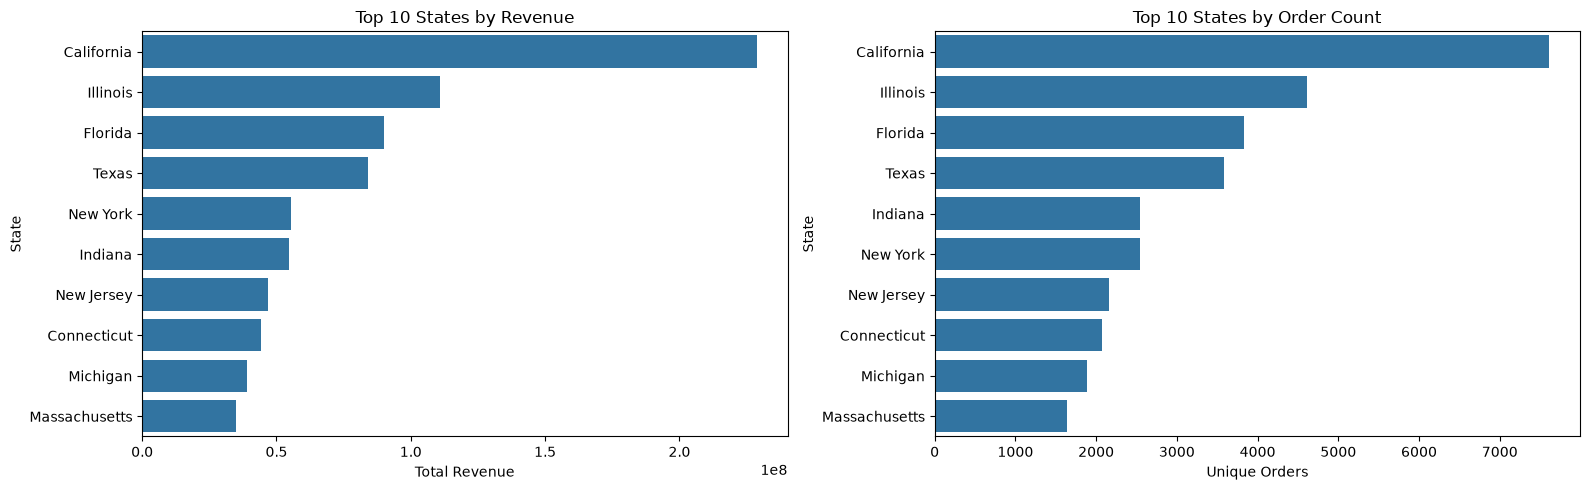

In [199]:

# Aggregate state-level metrics
state_sales = (
    df.groupby(['state_name', 'state_code'], as_index=False)
      .agg(
          revenue=('revenue', 'sum'),
          order_count=('order_number', 'nunique')
      )
)

# Top 10 states
top_revenue_states = state_sales.nlargest(10, 'revenue')
top_order_states = state_sales.nlargest(10, 'order_count')

# Side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(
    data=top_revenue_states,
    x='revenue',
    y='state_name',
    ax=axes[0]
)
axes[0].set_title('Top 10 States by Revenue')
axes[0].set_xlabel('Total Revenue')
axes[0].set_ylabel('State')

sns.barplot(
    data=top_order_states,
    x='order_count',
    y='state_name',
    ax=axes[1]
)
axes[1].set_title('Top 10 States by Order Count')
axes[1].set_xlabel('Unique Orders')
axes[1].set_ylabel('State')

plt.tight_layout()
plt.show()


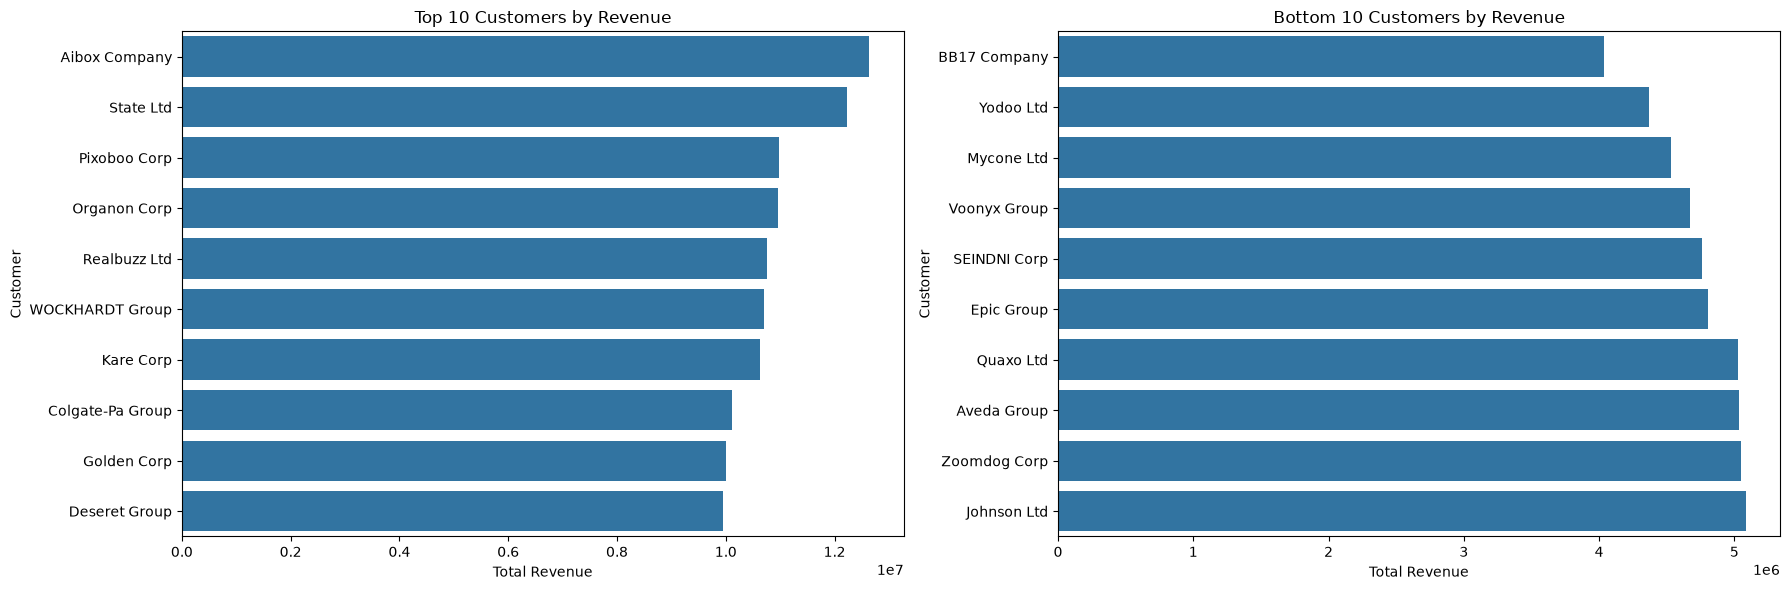

In [200]:
# Aggregate customer-level metrics
customer_sales = (
    df.groupby('customer_name', as_index=False)
      .agg(
          revenue=('revenue', 'sum'),
          profit=('profit', 'sum'),
          order_count=('order_number', 'nunique')
      )
)

# Top and bottom 10 customers
top_customers = customer_sales.nlargest(10, 'revenue')
bottom_customers = customer_sales.nsmallest(10, 'revenue')

# Side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=top_customers.sort_values('revenue', ascending=False),
    x='revenue',
    y='customer_name',
    ax=axes[0]
)
axes[0].set_title('Top 10 Customers by Revenue')
axes[0].set_xlabel('Total Revenue')
axes[0].set_ylabel('Customer')

sns.barplot(
    data=bottom_customers.sort_values('revenue'),
    x='revenue',
    y='customer_name',
    ax=axes[1]
)
axes[1].set_title('Bottom 10 Customers by Revenue')
axes[1].set_xlabel('Total Revenue')
axes[1].set_ylabel('Customer')

plt.tight_layout()
plt.show()

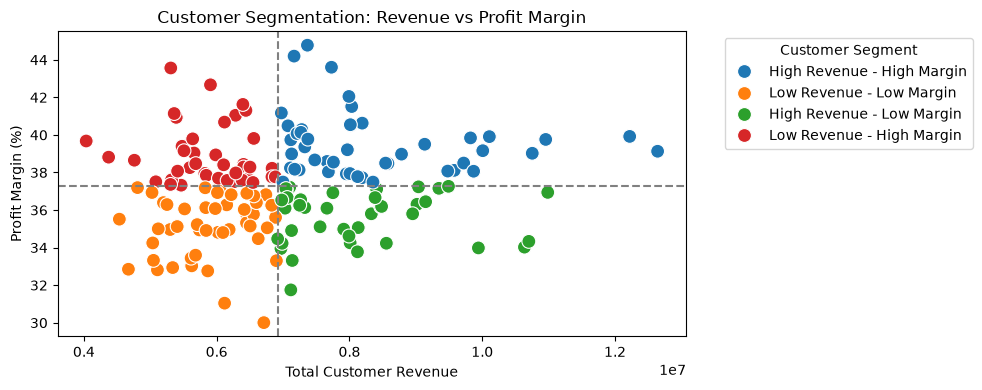

,segment,customers,total_revenue,total_profit,avg_profit_margin_pct
0,High Revenue - High Margin,48,399318057.0,1.573544e+08,39.437984
1,High Revenue - Low Margin,40,324449376.0,1.156606e+08,35.640750
3,Low Revenue - Low Margin,47,277372000.2,9.738442e+07,35.093859
2,Low Revenue - High Margin,40,234829465.8,9.137316e+07,38.932561


In [201]:
# Aggregate customer metrics
customer_segments = (
    df.groupby('customer_name', as_index=False)
      .agg(
          revenue=('revenue', 'sum'),
          profit=('profit', 'sum'),
          order_count=('order_number', 'nunique')
      )
)

# Calculate weighted profit margin
customer_segments['profit_margin_pct'] = np.where(
    customer_segments['revenue'] != 0,
    customer_segments['profit'] / customer_segments['revenue'] * 100,
    np.nan
)

# Split customers using median revenue and median margin
revenue_median = customer_segments['revenue'].median()
margin_median = customer_segments['profit_margin_pct'].median()

customer_segments['segment'] = np.select(
    [
        (customer_segments['revenue'] >= revenue_median) &
        (customer_segments['profit_margin_pct'] >= margin_median),

        (customer_segments['revenue'] >= revenue_median) &
        (customer_segments['profit_margin_pct'] < margin_median),

        (customer_segments['revenue'] < revenue_median) &
        (customer_segments['profit_margin_pct'] >= margin_median),

        (customer_segments['revenue'] < revenue_median) &
        (customer_segments['profit_margin_pct'] < margin_median)
    ],
    [
        'High Revenue - High Margin',
        'High Revenue - Low Margin',
        'Low Revenue - High Margin',
        'Low Revenue - Low Margin'
    ],
    default='Margin unavailable'
)

# Scatter plot
plt.figure(figsize=(10,4))

sns.scatterplot(
    data=customer_segments,
    x='revenue',
    y='profit_margin_pct',
    hue='segment',
    s=100
)

plt.axvline(revenue_median, linestyle='--', color='grey')
plt.axhline(margin_median, linestyle='--', color='grey')

plt.title('Customer Segmentation: Revenue vs Profit Margin')
plt.xlabel('Total Customer Revenue')
plt.ylabel('Profit Margin (%)')
plt.legend(title='Customer Segment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Segment-level summary
segment_summary = (
    customer_segments.groupby('segment', as_index=False)
      .agg(
          customers=('customer_name', 'nunique'),
          total_revenue=('revenue', 'sum'),
          total_profit=('profit', 'sum'),
          avg_profit_margin_pct=('profit_margin_pct', 'mean')
      )
      .sort_values('total_revenue', ascending=False)
)

display(segment_summary)

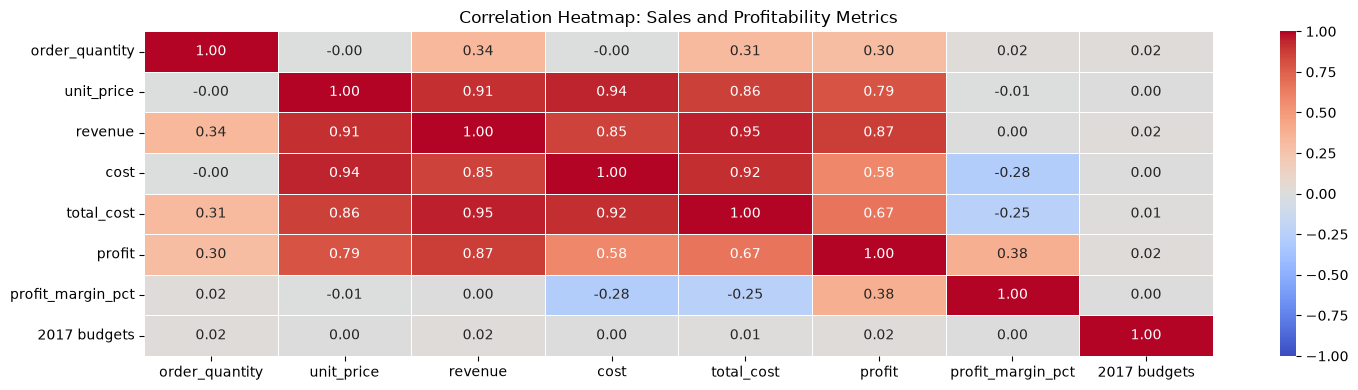

In [202]:
# Select numerical metrics relevant to sales and profitability
numeric_cols = [
    'order_quantity',
    'unit_price',
    'revenue',
    'cost',
    'total_cost',
    'profit',
    'profit_margin_pct',
    '2017 budgets'
]

# Keep only columns that exist in the DataFrame
numeric_cols = [col for col in numeric_cols if col in df.columns]

# Convert selected columns to numeric if necessary
numeric_df = df[numeric_cols].apply(
    pd.to_numeric,
    errors='coerce'
)

# Correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(15,4))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation Heatmap: Sales and Profitability Metrics')
plt.tight_layout()
plt.show()